#
**<h1 align="center">$\textbf{LAB Report: ODE}$</h1>**

<h4 align="right">$Name: Ahtasham Haider$</4>
<h4 align="right">$SC Code: SC26M004$</4>

---



# **Leapfrog Method**

The leapfrog method is a numerical method used to solve differential equations, especially when you want to simulate how something changes over time.

#### **The mathematical idea:** Consider a system whose motion is described by Newton's second law

<h2 align="center">$\frac{d^2x}{dt^2} = a(x)$</h2>

Here, $a(x)$ is the acceleration, which may depend on position.

This is a second-order differential equation, we can rewrite it as two first-order equations:

<h2 align="center">$\frac{dx}{dt} = v$</h2>

<h2 align="center">$\frac{dv}{dt} = a(x)$</h2>


The leapfrog method approximates both changes using a small time step $\Delta t$.

The two update rules

Step 1: Update velocity by half a time step.

<h3 align="center">$v_{n+1/2} = v_{n-1/2} + \Delta t \cdot a(x_n)$</h3>


Step 2: Update position by a full time step.

<h3 align="center">$x_{n+1} = x_n + \Delta t \cdot v_{n + 1/2}$</h3>

Then repeat the process using the new position.

Notice the staggered timing:

*   Velocity jumps from $t - Δt/2$ to $t + Δt/2$
*   Position jumps from $t$ to $t + Δt$




> [**REF**](https://chatgpt.com/s/t_6ad3a6e9e2308191ae737c6c9091816f)




## **Problem Statement:**

*   **Electron plasma oscillation**: An electron displaced from equilibrium in a uniform, fixed ion background feels an electric field
proportional to its displacement, and oscillates at the plasma frequency ωp. In normalized units
(ωp = 1), the motion is

<h2 align="center">$\frac{dx}{dt} = v, \quad \frac{dv}{dt} = -\omega_p^2x, \quad \omega_p=1$</h2>

<h3 align="center">$x(0) = 0.5, \quad v(0) = 0, \quad 0 ≤t≤20$</h3>


*   **Exact solution:**:

<h3 align="center">$x(t) = 0.5cost,\quad v(t) = - 0.5sint$</h3>


## **Required packages**

In [3]:
# do not change line below
from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Initialize

x_0 = 0.5
v_0 = 0

t = (0, 20)

h = 0.05
n = int((t[1] - t[0])/h + 1)

# Compute the staggered starting velocity from:---->        v_{-1/2} = v_0 - h/2*a(x_0)
v_i = v_0 + h/2*x_0

t_step = np.linspace(t[0], t[1], n)

t_step = np.arange(t[0], t[1] + h/2, h)
n = len(t_step)

x, v = np.zeros_like(t_step), np.zeros_like(t_step)
x[0], v[0] = x_0, v_i

In [5]:
def leapfrog(x, v, h):
    v = v - h*x
    x = x + h*v
    return x, v

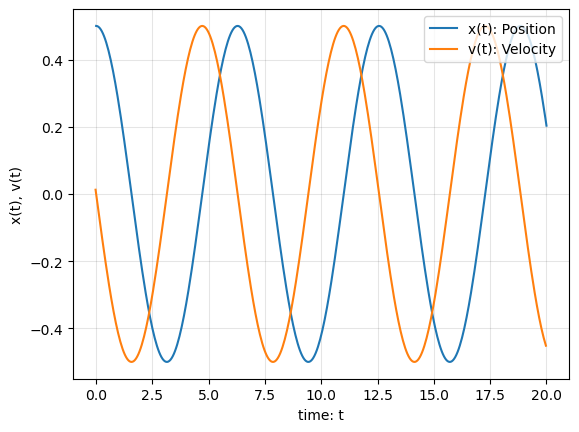

In [6]:
for i in range(1, n):
    x[i], v[i] = leapfrog(x[i-1], v[i-1], h)

plt.plot(t_step, x, label='x(t): Position')
plt.plot(t_step - h/2, v, label='v(t): Velocity')
plt.grid(True, color='black', alpha = 0.1)
plt.legend(loc='upper right')
plt.xlabel('time: t')
plt.ylabel('x(t), v(t)')
plt.show()

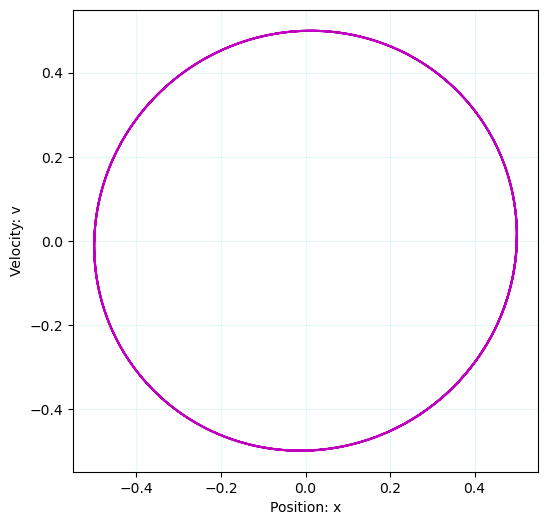

In [7]:
plt.figure(figsize=(6, 6))
plt.plot(x, v, "m")
plt.xlabel('Position: x')
plt.ylabel('Velocity: v')
plt.grid(True, color='c', alpha = 0.1)
plt.show()

## **Convergence Analysis**

In [10]:
h = np.linspace(0.2, 0.01, 20)
err = np.zeros_like(h)

for i in range(len(h)):
    v_i = v_0 + h[i]/2*x_0

    t_step = np.arange(t[0], t[1] + h[i]/2, h[i])
    n = len(t_step)

    x_org = 0.5*np.cos(t_step)
    v_org = -0.5*np.sin(t_step - h[i]/2)

    x, v = np.zeros_like(t_step), np.zeros_like(t_step)
    x[0], v[0] = x_0, v_i

    for j in range(1, n):
        x[j], v[j] = leapfrog(x[j-1], v[j-1], h[i])
    err[i] = np.max(np.abs(x_org - x))

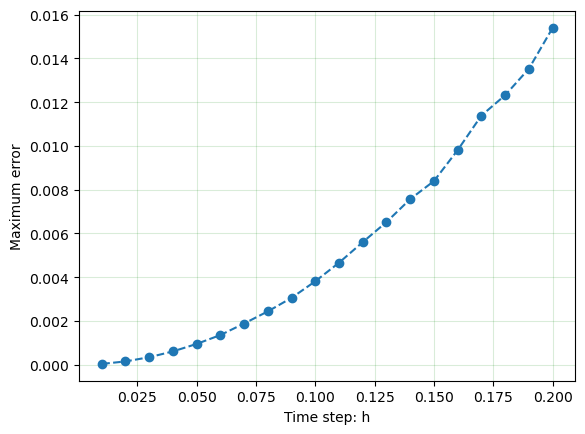

In [9]:
plt.plot(h, err, "o--")
plt.xlabel('Time step: h')
plt.ylabel('Maximum error')
plt.grid(True, color='g', alpha=0.15)
plt.show()

## **Derivation to Find the Order of the Method**

We start with the two core coupled update equations of the Leapfrog scheme:

$$v_{n+1/2} = v_{n-1/2} + h \cdot a(x_n) \quad \quad \text{--- (1)}$$

$$x_{n+1} = x_n + h \cdot v_{n + 1/2} \quad \text{--- (2)}$$

#### Step 1: Express velocities in terms of positions
Rearranging equation (2) allows us to isolate the forward half-step velocity:

$$v_{n + 1/2} = \frac{x_{n+1} - x_{n}}{h} \quad \text{--- (3)}$$

By shifting the index of equation (3) backward by one time step ($n \rightarrow n-1$), we find the expression for the backward half-step velocity:

$$v_{n - 1/2} = \frac{x_{n} - x_{n-1}}{h} \quad \text{--- (4)}$$

#### Step 2: Substitute and simplify
Substituting equations (3) and (4) into equation (1), and substituting the electron plasma acceleration $a(x_n) = -\omega_p^2 x_n$, we get:

$$\frac{x_{n+1} - x_{n}}{h} = \frac{x_{n} - x_{n-1}}{h} - h\omega_p^2 x_n$$

Multiplying the entire equation by $h$ to clear the denominators:

$$x_{n+1} - x_{n} = x_{n} - x_{n-1} - \omega_p^2 h^2 x_n$$

#### Step 3: Rearrange terms
Gathering all position variables onto the left-hand side yields the final **central-difference formula**:

$$\mathbf{x_{n+1} - 2x_n + x_{n-1} = -\omega_p^2 h^2 x_n}$$
